In [15]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
connection=sqlite3.connect('olist_cohort.db') #sqlite bazasina qosuluruq

In [5]:
pd.read_sql_query( #view nun isleyib islemediyini yoxlayiriq
    "SELECT * FROM v_order_analytics LIMIT 5",
    connection
)

,order_id,customer_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,price,freight_value,product_category_name,product_category_name_english,review_score,review_count
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18 00:00:00,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,29.99,8.72,None,Unknown,None,0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13 00:00:00,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,118.70,22.76,None,Unknown,None,0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04 00:00:00,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,159.90,19.22,None,Unknown,None,0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15 00:00:00,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,45.00,27.20,None,Unknown,None,0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26 00:00:00,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,19.90,8.72,None,Unknown,None,0


,month,total_revenue
0,2016-09,134.97
1,2016-10,40325.11
2,2016-12,10.90
3,2017-01,111798.36
4,2017-02,234223.40


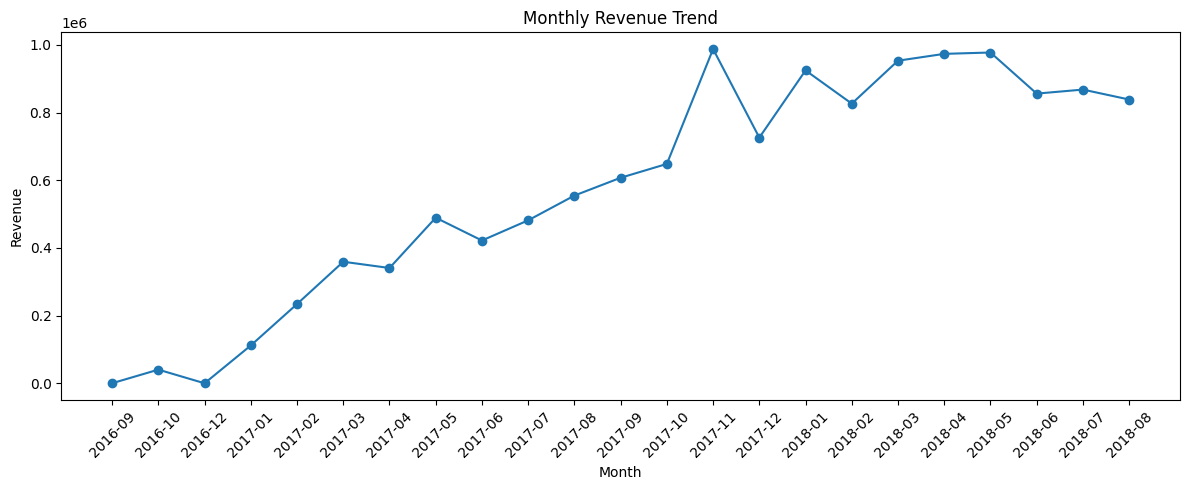

In [6]:
#burada gelirin hansi aylarda artib azaldigina baxiriq
monthly_query = """
SELECT strftime('%Y-%m', order_purchase_timestamp) AS month,
ROUND(SUM(price), 2) AS total_revenue
FROM v_order_analytics
WHERE order_status = 'delivered'
GROUP BY strftime('%Y-%m', order_purchase_timestamp)
ORDER BY month;
"""
monthly_df = pd.read_sql_query(monthly_query, connection)

display(monthly_df.head())

plt.figure(figsize=(12, 5))
plt.plot(monthly_df["month"],monthly_df["total_revenue"],marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
#burda kateqoriyalari gelirlere gore muqayise edirik
category_query = """
SELECT product_category_name_english AS category,
ROUND(SUM(price), 2) AS total_revenue
FROM v_order_analytics
WHERE order_status = 'delivered'
AND product_category_name_english IS NOT NULL
AND product_category_name_english <> 'Unknown'
GROUP BY product_category_name_english
ORDER BY total_revenue DESC;
"""

category_df = pd.read_sql_query(category_query, connection)

top5 = category_df.head(5)
bottom5 = category_df.tail(5).sort_values("total_revenue")

display(top5)
display(bottom5)

,category,total_revenue


,category,total_revenue


In [ ]:
#en cox gelir getiren 5 kateqoriya
plt.figure(figsize=(10, 5))
plt.barh(top5["category"], top5["total_revenue"])
plt.title("Top 5 Categories by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Category")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
#en az gelir getiren 5 kateqoriya
plt.figure(figsize=(10, 5))
plt.barh(bottom5["category"], bottom5["total_revenue"])
plt.title("Bottom 5 Categories by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [12]:
#burda her sifarisin verilme tarixi catdirilma tarixi ve musteri reyi var
q10_query = """
SELECT order_id,
MAX(order_purchase_timestamp) AS purchase_date,
MAX(order_delivered_customer_date) AS delivery_date,
MAX(review_score) AS review_score
FROM v_order_analytics
WHERE order_status = 'delivered'
GROUP BY order_id;
"""

delivery_df = pd.read_sql_query(q10_query, connection)
#burada tarixi datetime formatina ceviririk
delivery_df["purchase_date"] = pd.to_datetime( delivery_df["purchase_date"])

delivery_df["delivery_date"] = pd.to_datetime(delivery_df["delivery_date"])

delivery_df["delivery_days"] = (delivery_df["delivery_date"] - delivery_df["purchase_date"]).dt.total_seconds() / 86400
#catdirilma tarixinden alis tarixini cixib ferqi saniyeye cevirib onu da bir gundeki saniye sayina bolub gunleri tapiriq
delivery_df = delivery_df.dropna(subset=["delivery_days", "review_score"])

display(delivery_df.head())

,order_id,purchase_date,delivery_date,review_score,delivery_days


In [19]:
#burada catdirilma muddeti ile rey bali arasindaki korrelyasiyani hesablayiriq
correlation = delivery_df[["delivery_days", "review_score"]].corr().loc["delivery_days", "review_score"]
#eger korrelyasiya +1 ə yaxin olarsa deyisenler arasinda guclu musbet elaqe var demekdir(yeni biri artdiqca o biri de artirsa)
#eger -1 e yaxin olarsa biri artdiqca o biri deyer azalir demekdir
print("Delivery vs Review correlation:", round(correlation, 3))

Delivery vs Review correlation: nan


In [ ]:
plt.figure(figsize=(9, 5))
#her sifarisi ayrica noqte kimi gosterir
plt.scatter(delivery_df["delivery_days"],delivery_df["review_score"],alpha=0.3)

x = delivery_df["delivery_days"].to_numpy(dtype=float)
y = delivery_df["review_score"].to_numpy(dtype=float)

slope, intercept = np.polyfit(x, y, 1)

plt.plot(x.sort_values(),slope * x.sort_values() + intercept) #trend xettini cekir

plt.title("Delivery Time vs Review Score")
plt.xlabel("Delivery Days")
plt.ylabel("Review Score")
plt.tight_layout()
plt.show()